# Apache Spark + Apache Iceberg

Notebook que demonstra a criação de tabelas no formato **Apache Iceberg** com **PySpark** em ambiente local,
e os comandos **INSERT**, **UPDATE** e **DELETE** (além de `MERGE`, snapshots e *time travel*).

**Versões:** Python 3.11 · PySpark 3.5.3 · iceberg-spark-runtime-3.5_2.12 1.6.1 · Java 17

**Roteiro:** 1. Cenário → 2. Ambiente → 3. DDL → 4. INSERT → 5. UPDATE → 6. DELETE → 7. MERGE → 8. Snapshots e time travel → 9. Arquivos no disco

## 1. Cenário

Para os exemplos usamos uma **academia** fictícia. É um cenário fácil de entender:

- a academia vende **planos** (Mensal, Trimestral, Anual);
- cada **aluno** está matriculado em um plano;
- toda vez que o aluno chega na academia e passa na catraca, é gravado um **check-in**.

O **conjunto de dados foi criado por nós** (não foi baixado de nenhum site): são poucos registros escritos
direto nos comandos `INSERT`, para que dê para conferir com os olhos o efeito de cada `UPDATE` e `DELETE`.

### Modelo ER

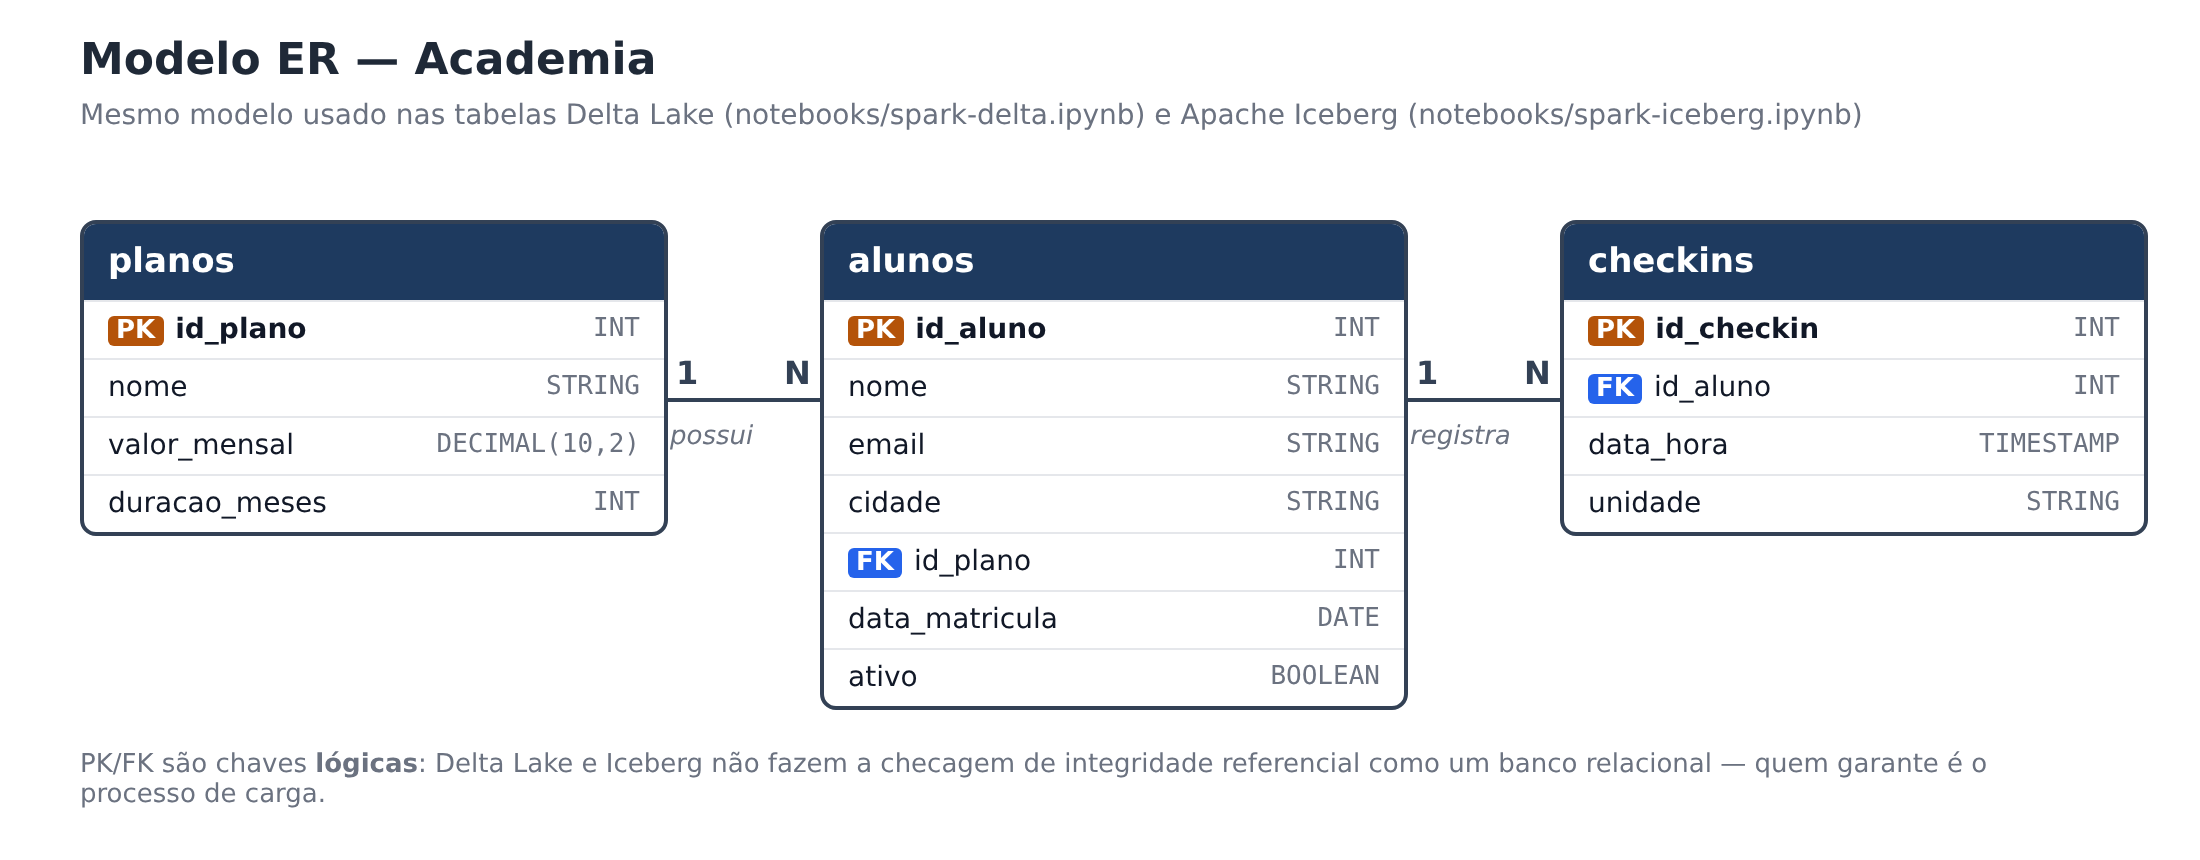

| Tabela | O que guarda | Relacionamento |
|---|---|---|
| `planos` | os planos vendidos e seu valor mensal | 1 plano → N alunos |
| `alunos` | cadastro dos alunos e o plano de cada um | 1 aluno → N check-ins |
| `checkins` | cada entrada do aluno na academia | — |

> **Importante:** as chaves primárias (PK) e estrangeiras (FK) do diagrama são **lógicas**.
> Formatos de tabela de Data Lake (Delta e Iceberg) não bloqueiam um `INSERT` com chave repetida
> nem um `id_plano` que não existe, como faria um PostgreSQL. A integridade é responsabilidade do processo de carga.

## 2. Preparando o ambiente

### 2.1 Conferindo versões

In [1]:
import sys, shutil, platform
import pyspark

print("Python  :", sys.version.split()[0])
print("PySpark :", pyspark.__version__)
print("Sistema :", platform.platform())
print("Java    :", shutil.which("java") or "NÃO ENCONTRADO - instale o openjdk-17-jdk (veja o README)")

Python  : 3.11.17
PySpark : 3.5.3
Sistema : Linux-6.18.33.2-microsoft-standard-WSL2-x86_64-with-glibc2.39
Java    : /usr/bin/java


### 2.2 Pasta onde as tabelas serão gravadas

As tabelas ficam em `spark-warehouse/iceberg/` na raiz do projeto. Esta célula **apaga essa pasta**
para o notebook rodar sempre do zero.

In [2]:
import shutil
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
WAREHOUSE = ROOT / "spark-warehouse" / "iceberg"

shutil.rmtree(WAREHOUSE, ignore_errors=True)
print("Warehouse Iceberg:", WAREHOUSE)

Warehouse Iceberg: /home/kaualucas/projetos/spark-delta-iceberg/spark-warehouse/iceberg


### 2.3 Criando a SparkSession com Apache Iceberg

O Iceberg trabalha com **catálogos**. Aqui criamos um catálogo chamado **`local`** do tipo `hadoop`,
que guarda tudo em pastas no próprio disco (não precisa de servidor). Por isso as tabelas são chamadas
`local.academia.<tabela>` → `catálogo.namespace.tabela`.

| Configuração | Para que serve |
|---|---|
| `spark.jars.packages` | baixa o `.jar` do Iceberg compatível com Spark 3.5 (Scala 2.12) |
| `spark.sql.extensions` | habilita no Spark SQL os comandos do Iceberg (`UPDATE`, `DELETE`, `MERGE`, `CALL`...) |
| `spark.sql.catalog.local` | cria o catálogo `local` usando a implementação do Iceberg |
| `spark.sql.catalog.local.type` | `hadoop` = metadados guardados em arquivos, sem servidor |
| `spark.sql.catalog.local.warehouse` | pasta onde o catálogo grava as tabelas |

> **Primeira execução:** o Spark baixa automaticamente da internet (Maven Central) o pacote `.jar` do Apache Iceberg
> e guarda em `~/.ivy2`. Por isso a primeira vez demora um pouco e **precisa de internet**. Nas próximas vezes é instantâneo.

In [3]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("SparkIceberg")
    .master("local[*]")
    .config("spark.jars.packages", "org.apache.iceberg:iceberg-spark-runtime-3.5_2.12:1.6.1")
    .config("spark.sql.extensions", "org.apache.iceberg.spark.extensions.IcebergSparkSessionExtensions")
    .config("spark.sql.catalog.local", "org.apache.iceberg.spark.SparkCatalog")
    .config("spark.sql.catalog.local.type", "hadoop")
    .config("spark.sql.catalog.local.warehouse", str(WAREHOUSE))
    .config("spark.sql.warehouse.dir", str(WAREHOUSE))
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
spark

26/10/04 14:51:48 WARN Utils: Your hostname, Kau resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/10/04 14:51:48 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


:: loading settings :: url = jar:file:/home/kaualucas/projetos/spark-delta-iceberg/.venv/lib/python3.11/site-packages/pyspark/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /home/kaualucas/.ivy2/cache
The jars for the packages stored in: /home/kaualucas/.ivy2/jars
org.apache.iceberg#iceberg-spark-runtime-3.5_2.12 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-451a2512-0c0b-4b07-b7ee-13b8a0df3e3e;1.0
	confs: [default]
	found org.apache.iceberg#iceberg-spark-runtime-3.5_2.12;1.6.1 in central
downloading https://repo1.maven.org/maven2/org/apache/iceberg/iceberg-spark-runtime-3.5_2.12/1.6.1/iceberg-spark-runtime-3.5_2.12-1.6.1.jar ...
	[SUCCESSFUL ] org.apache.iceberg#iceberg-spark-runtime-3.5_2.12;1.6.1!iceberg-spark-runtime-3.5_2.12.jar (2386ms)
:: resolution report :: resolve 2191ms :: artifacts dl 2390ms
	:: modules in use:
	org.apache.iceberg#iceberg-spark-runtime-3.5_2.12;1.6.1 from central in [default]
	---------------------------------------------------------------------
	|                  |            modules            ||   artifacts   |
	|       conf       | number| search|dwnlded|

## 3. DDL — criação do namespace e das tabelas

`USING iceberg` cria a tabela no formato Iceberg: os dados ficam em arquivos **Parquet** (pasta `data/`) e
os metadados em uma pasta **`metadata/`** (arquivos `.json` e `.avro`) que guardam o esquema, as partições e
a lista de **snapshots** (fotografias da tabela a cada alteração).

Na tabela `checkins` usamos o **particionamento oculto** (*hidden partitioning*), um recurso marcante do Iceberg:
`PARTITIONED BY (days(data_hora))` particiona por **dia** a partir da coluna de data/hora, sem precisar criar
uma coluna extra só para a partição. Quem consulta continua filtrando por `data_hora` normalmente.

In [4]:
spark.sql("CREATE NAMESPACE IF NOT EXISTS local.academia")

DataFrame[]

In [5]:
spark.sql("""
CREATE TABLE IF NOT EXISTS local.academia.planos (
    id_plano      INT,
    nome          STRING,
    valor_mensal  DECIMAL(10,2),
    duracao_meses INT
) USING iceberg
""")

DataFrame[]

In [6]:
spark.sql("""
CREATE TABLE IF NOT EXISTS local.academia.alunos (
    id_aluno       INT,
    nome           STRING,
    email          STRING,
    cidade         STRING,
    id_plano       INT,
    data_matricula DATE,
    ativo          BOOLEAN
) USING iceberg
""")

DataFrame[]

In [7]:
spark.sql("""
CREATE TABLE IF NOT EXISTS local.academia.checkins (
    id_checkin INT,
    id_aluno   INT,
    data_hora  TIMESTAMP,
    unidade    STRING
) USING iceberg
PARTITIONED BY (days(data_hora))
""")

DataFrame[]

In [8]:
spark.sql("SHOW TABLES IN local.academia").show()
spark.sql("DESCRIBE TABLE local.academia.checkins").show(truncate=False)

+---------+---------+-----------+
|namespace|tableName|isTemporary|
+---------+---------+-----------+
| academia|   alunos|      false|
| academia| checkins|      false|
| academia|   planos|      false|
+---------+---------+-----------+

+--------------+---------------+-------+
|col_name      |data_type      |comment|
+--------------+---------------+-------+
|id_checkin    |int            |NULL   |
|id_aluno      |int            |NULL   |
|data_hora     |timestamp      |NULL   |
|unidade       |string         |NULL   |
|              |               |       |
|# Partitioning|               |       |
|Part 0        |days(data_hora)|       |
+--------------+---------------+-------+



## 4. INSERT

### 4.1 INSERT com SQL

In [9]:
spark.sql("""
INSERT INTO local.academia.planos VALUES
  (1, 'Mensal',     99.90,  1),
  (2, 'Trimestral', 269.70, 3),
  (3, 'Anual',      899.00, 12)
""")

DataFrame[]

In [10]:
spark.sql("""
INSERT INTO local.academia.alunos VALUES
  (1, 'Ana Souza',     'ana@email.com',   'Criciúma',     1, DATE '2024-01-10', true),
  (2, 'Bruno Lima',    'bruno@email.com', 'Içara',        3, DATE '2024-02-05', true),
  (3, 'Carla Mendes',  'carla@email.com', 'Criciúma',     2, DATE '2024-03-12', true),
  (4, 'Diego Rocha',   'diego@email.com', 'Forquilhinha', 1, DATE '2024-04-20', false),
  (5, 'Elisa Martins', 'elisa@email.com', 'Criciúma',     3, DATE '2024-05-02', true)
""")

DataFrame[]

In [11]:
spark.sql("""
INSERT INTO local.academia.checkins VALUES
  (1, 1, TIMESTAMP '2024-06-03 07:15:00', 'Centro'),
  (2, 2, TIMESTAMP '2024-06-03 18:40:00', 'Próspera'),
  (3, 1, TIMESTAMP '2024-06-04 07:05:00', 'Centro'),
  (4, 3, TIMESTAMP '2024-06-04 19:10:00', 'Centro'),
  (5, 4, TIMESTAMP '2024-06-05 06:50:00', 'Próspera'),
  (6, 5, TIMESTAMP '2024-06-05 12:30:00', 'Centro'),
  (7, 4, TIMESTAMP '2024-06-06 06:55:00', 'Próspera'),
  (8, 2, TIMESTAMP '2024-06-06 18:20:00', 'Próspera')
""")

DataFrame[]

In [12]:
spark.sql("SELECT * FROM local.academia.planos ORDER BY id_plano").show()
spark.sql("SELECT * FROM local.academia.alunos ORDER BY id_aluno").show()
spark.sql("SELECT * FROM local.academia.checkins ORDER BY id_checkin").show()

+--------+----------+------------+-------------+
|id_plano|      nome|valor_mensal|duracao_meses|
+--------+----------+------------+-------------+
|       1|    Mensal|       99.90|            1|
|       2|Trimestral|      269.70|            3|
|       3|     Anual|      899.00|           12|
+--------+----------+------------+-------------+

+--------+-------------+---------------+------------+--------+--------------+-----+
|id_aluno|         nome|          email|      cidade|id_plano|data_matricula|ativo|
+--------+-------------+---------------+------------+--------+--------------+-----+
|       1|    Ana Souza|  ana@email.com|    Criciúma|       1|    2024-01-10| true|
|       2|   Bruno Lima|bruno@email.com|       Içara|       3|    2024-02-05| true|
|       3| Carla Mendes|carla@email.com|    Criciúma|       2|    2024-03-12| true|
|       4|  Diego Rocha|diego@email.com|Forquilhinha|       1|    2024-04-20|false|
|       5|Elisa Martins|elisa@email.com|    Criciúma|       3|    20

### 4.2 INSERT com DataFrame (API PySpark)
Para Iceberg, a forma recomendada de gravar um DataFrame é a API `writeTo(...)`, aqui com `.append()` (acrescentar).

In [13]:
from datetime import date

novo_aluno = spark.createDataFrame(
    [(6, "Felipe Costa", "felipe@email.com", "Criciúma", 2, date(2024, 6, 10), True)],
    schema="id_aluno INT, nome STRING, email STRING, cidade STRING, id_plano INT, data_matricula DATE, ativo BOOLEAN",
)
novo_aluno.show()

+--------+------------+----------------+--------+--------+--------------+-----+
|id_aluno|        nome|           email|  cidade|id_plano|data_matricula|ativo|
+--------+------------+----------------+--------+--------+--------------+-----+
|       6|Felipe Costa|felipe@email.com|Criciúma|       2|    2024-06-10| true|
+--------+------------+----------------+--------+--------+--------------+-----+



In [14]:
novo_aluno.writeTo("local.academia.alunos").append()

spark.sql("SELECT * FROM local.academia.alunos ORDER BY id_aluno").show()

+--------+-------------+----------------+------------+--------+--------------+-----+
|id_aluno|         nome|           email|      cidade|id_plano|data_matricula|ativo|
+--------+-------------+----------------+------------+--------+--------------+-----+
|       1|    Ana Souza|   ana@email.com|    Criciúma|       1|    2024-01-10| true|
|       2|   Bruno Lima| bruno@email.com|       Içara|       3|    2024-02-05| true|
|       3| Carla Mendes| carla@email.com|    Criciúma|       2|    2024-03-12| true|
|       4|  Diego Rocha| diego@email.com|Forquilhinha|       1|    2024-04-20|false|
|       5|Elisa Martins| elisa@email.com|    Criciúma|       3|    2024-05-02| true|
|       6| Felipe Costa|felipe@email.com|    Criciúma|       2|    2024-06-10| true|
+--------+-------------+----------------+------------+--------+--------------+-----+



### 4.3 Consultando com JOIN

In [15]:
spark.sql("""
SELECT a.id_aluno, a.nome, p.nome AS plano, p.valor_mensal, COUNT(c.id_checkin) AS qtd_checkins
FROM local.academia.alunos a
JOIN local.academia.planos p   ON p.id_plano = a.id_plano
LEFT JOIN local.academia.checkins c ON c.id_aluno = a.id_aluno
GROUP BY a.id_aluno, a.nome, p.nome, p.valor_mensal
ORDER BY a.id_aluno
""").show()

+--------+-------------+----------+------------+------------+
|id_aluno|         nome|     plano|valor_mensal|qtd_checkins|
+--------+-------------+----------+------------+------------+
|       1|    Ana Souza|    Mensal|       99.90|           2|
|       2|   Bruno Lima|     Anual|      899.00|           2|
|       3| Carla Mendes|Trimestral|      269.70|           1|
|       4|  Diego Rocha|    Mensal|       99.90|           2|
|       5|Elisa Martins|     Anual|      899.00|           1|
|       6| Felipe Costa|Trimestral|      269.70|           0|
+--------+-------------+----------+------------+------------+



## 5. UPDATE

Assim como no Delta, o Iceberg permite `UPDATE` com SQL comum. Por padrão ele usa a estratégia
**copy-on-write**: reescreve os arquivos Parquet que contêm as linhas alteradas e cria um **novo snapshot**.

### 5.1 Reajuste de 10% no plano Mensal

In [16]:
spark.sql("""
UPDATE local.academia.planos
SET valor_mensal = ROUND(valor_mensal * 1.10, 2)
WHERE nome = 'Mensal'
""")

spark.sql("SELECT * FROM local.academia.planos ORDER BY id_plano").show()

+--------+----------+------------+-------------+
|id_plano|      nome|valor_mensal|duracao_meses|
+--------+----------+------------+-------------+
|       1|    Mensal|      109.89|            1|
|       2|Trimestral|      269.70|            3|
|       3|     Anual|      899.00|           12|
+--------+----------+------------+-------------+



O plano Mensal passou de **99.90** para **109.89**.

### 5.2 A aluna Ana trocou o plano Mensal pelo Anual

In [17]:
spark.sql("UPDATE local.academia.alunos SET id_plano = 3 WHERE id_aluno = 1")

spark.sql("SELECT * FROM local.academia.alunos WHERE id_aluno = 1").show()

+--------+---------+-------------+--------+--------+--------------+-----+
|id_aluno|     nome|        email|  cidade|id_plano|data_matricula|ativo|
+--------+---------+-------------+--------+--------+--------------+-----+
|       1|Ana Souza|ana@email.com|Criciúma|       3|    2024-01-10| true|
+--------+---------+-------------+--------+--------+--------------+-----+



## 6. DELETE

O aluno **Diego (id 4)** está inativo e pediu o cancelamento. Removemos primeiro os check-ins dele e depois o cadastro.

In [18]:
spark.sql("DELETE FROM local.academia.checkins WHERE id_aluno = 4")
spark.sql("SELECT * FROM local.academia.checkins ORDER BY id_checkin").show()

+----------+--------+-------------------+--------+
|id_checkin|id_aluno|          data_hora| unidade|
+----------+--------+-------------------+--------+
|         1|       1|2024-06-03 07:15:00|  Centro|
|         2|       2|2024-06-03 18:40:00|Próspera|
|         3|       1|2024-06-04 07:05:00|  Centro|
|         4|       3|2024-06-04 19:10:00|  Centro|
|         6|       5|2024-06-05 12:30:00|  Centro|
|         8|       2|2024-06-06 18:20:00|Próspera|
+----------+--------+-------------------+--------+



In [19]:
spark.sql("DELETE FROM local.academia.alunos WHERE id_aluno = 4")
spark.sql("SELECT * FROM local.academia.alunos ORDER BY id_aluno").show()

+--------+-------------+----------------+--------+--------+--------------+-----+
|id_aluno|         nome|           email|  cidade|id_plano|data_matricula|ativo|
+--------+-------------+----------------+--------+--------+--------------+-----+
|       1|    Ana Souza|   ana@email.com|Criciúma|       3|    2024-01-10| true|
|       2|   Bruno Lima| bruno@email.com|   Içara|       3|    2024-02-05| true|
|       3| Carla Mendes| carla@email.com|Criciúma|       2|    2024-03-12| true|
|       5|Elisa Martins| elisa@email.com|Criciúma|       3|    2024-05-02| true|
|       6| Felipe Costa|felipe@email.com|Criciúma|       2|    2024-06-10| true|
+--------+-------------+----------------+--------+--------+--------------+-----+



## 7. MERGE (bônus: INSERT + UPDATE em um único comando)

Se o aluno **já existe**, atualiza; se **não existe**, insere (*upsert*).

In [20]:
atualizacoes = spark.createDataFrame(
    [
        # Carla (id 3) já existe: mudou de cidade -> será ATUALIZADA
        (3, "Carla Mendes",   "carla@email.com",    "Içara",    2, date(2024, 3, 12), True),
        # Gabriela (id 7) não existe -> será INSERIDA
        (7, "Gabriela Alves", "gabriela@email.com", "Criciúma", 1, date(2024, 6, 15), True),
    ],
    schema="id_aluno INT, nome STRING, email STRING, cidade STRING, id_plano INT, data_matricula DATE, ativo BOOLEAN",
)
atualizacoes.createOrReplaceTempView("atualizacoes_alunos")
atualizacoes.show()

+--------+--------------+------------------+--------+--------+--------------+-----+
|id_aluno|          nome|             email|  cidade|id_plano|data_matricula|ativo|
+--------+--------------+------------------+--------+--------+--------------+-----+
|       3|  Carla Mendes|   carla@email.com|   Içara|       2|    2024-03-12| true|
|       7|Gabriela Alves|gabriela@email.com|Criciúma|       1|    2024-06-15| true|
+--------+--------------+------------------+--------+--------+--------------+-----+



In [21]:
spark.sql("""
MERGE INTO local.academia.alunos AS destino
USING atualizacoes_alunos AS origem
ON destino.id_aluno = origem.id_aluno
WHEN MATCHED THEN UPDATE SET *
WHEN NOT MATCHED THEN INSERT *
""")

spark.sql("SELECT * FROM local.academia.alunos ORDER BY id_aluno").show()

+--------+--------------+------------------+--------+--------+--------------+-----+
|id_aluno|          nome|             email|  cidade|id_plano|data_matricula|ativo|
+--------+--------------+------------------+--------+--------+--------------+-----+
|       1|     Ana Souza|     ana@email.com|Criciúma|       3|    2024-01-10| true|
|       2|    Bruno Lima|   bruno@email.com|   Içara|       3|    2024-02-05| true|
|       3|  Carla Mendes|   carla@email.com|   Içara|       2|    2024-03-12| true|
|       5| Elisa Martins|   elisa@email.com|Criciúma|       3|    2024-05-02| true|
|       6|  Felipe Costa|  felipe@email.com|Criciúma|       2|    2024-06-10| true|
|       7|Gabriela Alves|gabriela@email.com|Criciúma|       1|    2024-06-15| true|
+--------+--------------+------------------+--------+--------+--------------+-----+



## 8. Snapshots e *time travel*

No Iceberg, cada alteração gera um **snapshot** identificado por um número (`snapshot_id`).
O Iceberg expõe **tabelas de metadados** que podem ser consultadas com SQL, adicionando um sufixo ao nome da tabela:
`.snapshots`, `.history`, `.files`, `.partitions`...

Diferente do Delta, o `CREATE TABLE` não gera snapshot: o primeiro aparece no primeiro INSERT.
Para a tabela `alunos` esperamos 5 snapshots: INSERT, append do Felipe, UPDATE, DELETE e MERGE.

In [22]:
spark.sql("""
SELECT committed_at, snapshot_id, parent_id, operation
FROM local.academia.alunos.snapshots
ORDER BY committed_at
""").show(truncate=False)

+-----------------------+-------------------+-------------------+---------+
|committed_at           |snapshot_id        |parent_id          |operation|
+-----------------------+-------------------+-------------------+---------+
|2026-10-04 14:52:18.495|2593495062122568043|NULL               |append   |
|2026-10-04 14:52:29.363|3450008486569556107|2593495062122568043|append   |
|2026-10-04 14:52:39.304|2654139964854947904|3450008486569556107|overwrite|
|2026-10-04 14:52:40.787|7059825771053043103|2654139964854947904|delete   |
|2026-10-04 14:52:49.465|2603173318217339332|7059825771053043103|overwrite|
+-----------------------+-------------------+-------------------+---------+



Consultando a tabela **como ela era no primeiro snapshot** (logo após o primeiro INSERT):
os 5 alunos originais, com a Ana no plano 1 e o Diego ainda cadastrado.

In [23]:
primeiro_snapshot = spark.sql("""
    SELECT snapshot_id FROM local.academia.alunos.snapshots ORDER BY committed_at LIMIT 1
""").first()["snapshot_id"]

print("Primeiro snapshot:", primeiro_snapshot)
spark.sql(f"SELECT * FROM local.academia.alunos VERSION AS OF {primeiro_snapshot} ORDER BY id_aluno").show()

Primeiro snapshot: 2593495062122568043
+--------+-------------+---------------+------------+--------+--------------+-----+
|id_aluno|         nome|          email|      cidade|id_plano|data_matricula|ativo|
+--------+-------------+---------------+------------+--------+--------------+-----+
|       1|    Ana Souza|  ana@email.com|    Criciúma|       1|    2024-01-10| true|
|       2|   Bruno Lima|bruno@email.com|       Içara|       3|    2024-02-05| true|
|       3| Carla Mendes|carla@email.com|    Criciúma|       2|    2024-03-12| true|
|       4|  Diego Rocha|diego@email.com|Forquilhinha|       1|    2024-04-20|false|
|       5|Elisa Martins|elisa@email.com|    Criciúma|       3|    2024-05-02| true|
+--------+-------------+---------------+------------+--------+--------------+-----+



Outras tabelas de metadados úteis — os arquivos de dados atuais e as partições da tabela `checkins`
(uma partição por dia, gerada pelo `days(data_hora)`):

In [24]:
spark.sql("SELECT file_path, record_count FROM local.academia.alunos.files").show(truncate=False)
spark.sql("SELECT partition, record_count, file_count FROM local.academia.checkins.partitions").show(truncate=False)

+--------------------------------------------------------------------------------------------------------------------------------------------------------+------------+
|file_path                                                                                                                                               |record_count|
+--------------------------------------------------------------------------------------------------------------------------------------------------------+------------+
|/home/kaualucas/projetos/spark-delta-iceberg/spark-warehouse/iceberg/academia/alunos/data/00000-110-01f0a855-1eda-48f1-872d-12af231cdf2e-0-00001.parquet|2           |
|/home/kaualucas/projetos/spark-delta-iceberg/spark-warehouse/iceberg/academia/alunos/data/00000-60-46336001-ba43-4550-9586-83aa7ddafca0-0-00001.parquet |1           |
|/home/kaualucas/projetos/spark-delta-iceberg/spark-warehouse/iceberg/academia/alunos/data/00011-44-f9325a9f-c045-44b0-a079-ac8704f3ccf2-0-00001.parquet |1     

## 9. Como a tabela fica no disco

- pasta **`data/`**: arquivos `.parquet` com os dados;
- pasta **`metadata/`**: `vN.metadata.json` (esquema e lista de snapshots, um por versão),
  `snap-*.avro` (manifest list) e `*-m0.avro` (manifests, que apontam para os arquivos de dados).

Na tabela `checkins`, as subpastas `data_hora_day=2024-06-03/` etc. mostram o particionamento por dia.

In [25]:
import os

def mostrar_arquivos(pasta):
    """Lista os arquivos da tabela como uma árvore (ignora arquivos .crc de checksum)."""
    pasta = str(pasta)
    for raiz, _, arquivos in sorted(os.walk(pasta)):
        nivel = raiz.replace(pasta, "").count(os.sep)
        print("  " * nivel + os.path.basename(raiz) + "/")
        for a in sorted(arquivos):
            if not a.endswith(".crc"):
                print("  " * (nivel + 1) + a)

In [26]:
mostrar_arquivos(WAREHOUSE / "academia" / "alunos")

alunos/
  data/
    00000-110-01f0a855-1eda-48f1-872d-12af231cdf2e-0-00001.parquet
    00000-3-1c482698-52a5-473d-8a0b-51613bb8a842-0-00001.parquet
    00000-60-46336001-ba43-4550-9586-83aa7ddafca0-0-00001.parquet
    00001-4-1c482698-52a5-473d-8a0b-51613bb8a842-0-00001.parquet
    00002-5-1c482698-52a5-473d-8a0b-51613bb8a842-0-00001.parquet
    00003-6-1c482698-52a5-473d-8a0b-51613bb8a842-0-00001.parquet
    00004-7-1c482698-52a5-473d-8a0b-51613bb8a842-0-00001.parquet
    00011-44-f9325a9f-c045-44b0-a079-ac8704f3ccf2-0-00001.parquet
  metadata/
    1bd11f37-ff7d-45fd-a331-cae4cf0c6a38-m0.avro
    261576a0-9c82-465a-b5f4-63b56dd67c50-m0.avro
    61c90d20-9ea9-465a-98f0-ca479015593f-m0.avro
    61c90d20-9ea9-465a-98f0-ca479015593f-m1.avro
    756750bd-f316-4456-bb78-573cb2d180af-m0.avro
    756750bd-f316-4456-bb78-573cb2d180af-m1.avro
    83cc019d-ba55-44e9-9678-10bea6929f14-m0.avro
    snap-2593495062122568043-1-83cc019d-ba55-44e9-9678-10bea6929f14.avro
    snap-2603173318217339332-1-7

In [27]:
mostrar_arquivos(WAREHOUSE / "academia" / "checkins")

checkins/
  data/
    data_hora_day=2024-06-03/
      00000-16-436d2a1f-cf5e-41aa-b167-6a9e442ffb75-0-00001.parquet
    data_hora_day=2024-06-04/
      00000-16-436d2a1f-cf5e-41aa-b167-6a9e442ffb75-0-00002.parquet
    data_hora_day=2024-06-05/
      00000-16-436d2a1f-cf5e-41aa-b167-6a9e442ffb75-0-00003.parquet
      00000-65-271fcf49-acc5-4af2-ab18-d17854401841-0-00001.parquet
    data_hora_day=2024-06-06/
      00000-16-436d2a1f-cf5e-41aa-b167-6a9e442ffb75-0-00004.parquet
      00000-65-271fcf49-acc5-4af2-ab18-d17854401841-0-00002.parquet
  metadata/
    64504991-eaac-4e98-b24a-0c62bd75587b-m0.avro
    64504991-eaac-4e98-b24a-0c62bd75587b-m1.avro
    d86c5bf6-74a4-4baa-b25e-a01469f155ad-m0.avro
    snap-8430475442834950773-1-d86c5bf6-74a4-4baa-b25e-a01469f155ad.avro
    snap-8969918481376622351-1-64504991-eaac-4e98-b24a-0c62bd75587b.avro
    v1.metadata.json
    v2.metadata.json
    v3.metadata.json
    version-hint.text


## 10. Encerrando

In [28]:
spark.stop()